In [32]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import TensorDataset , DataLoader

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report , confusion_matrix

import warnings
warnings.filterwarnings("ignore")

plt.style.use('default')
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12

np.random.seed(42)
torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

if torch.cuda.is_available():
    print(f"Running on : {torch.cuda.get_device_name()}")
    print(f"Total Device : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")
else:
    print("   Running on CPU")

print(f"Library Versions:")
print(f"PyTorch: {torch.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Matplotlib: {plt.matplotlib.__version__}")

print("\nEnvironment setup complete!")


cuda
Running on : NVIDIA GeForce RTX 4060 Laptop GPU
Total Device : 8.0 GB
Library Versions:
PyTorch: 2.11.0+cu128
NumPy: 2.4.1
Matplotlib: 3.10.8

Environment setup complete!


In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),         # Convert PIL Image to tensor (0 -> 225 --->>> 0 -> 1)
    transforms.Normalize( (0.2860,) , (0.3530,) )   # Normalize with Fashion-MNIST mean and std
])


# Fashion MNIST class names for visualization
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# Load train data 
train_dataset = torchvision.datasets.FashionMNIST(
    root = "./data",
    train = True,
    download = True,
    transform = transform,
)

# load test data
test_dataset = torchvision.datasets.FashionMNIST(
    root = "./data",
    train = False,
    download = True,
    transform = transform,
)

In [3]:

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size = BATCH_SIZE,
    shuffle = True,
    num_workers = 2
)

test_loader = DataLoader(
    test_dataset,
    batch_size = BATCH_SIZE,
    shuffle = True,
    num_workers = 2
)


## Model

In [5]:
class SimpleCNN(nn.Module):
    """ Initlize the Layers of our CNNs """
    
    def __init__(self):
        super().__init__()
        # First Convolutional Block
        self.conv1 = nn.Conv2d(
            in_channels = 1,
            out_channels = 32,
            kernel_size = 3,
            stride = 1,
            padding = 1,
        )
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2 , stride=2) # 2x2 max pooling

        # Second Convolutional Block
        self.conv2 = nn.Conv2d(
            in_channels = 32,
            out_channels = 64,
            kernel_size = 3,
            stride = 1,
            padding = 1,
        )
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2 , stride=2)


        # Third Convolutional Block
        self.conv3 = nn.Conv2d(
            in_channels = 64,
            out_channels = 128,
            kernel_size = 3,
            stride = 1,
            padding = 1,
        )
        self.relu3 = nn.ReLU()
        self.pool3 = nn.MaxPool2d(kernel_size=2 , stride=2)


        # Fully Connected Layer
        self.fc1 = nn.Linear(3*3*128 , 128)
        self.relu4 = nn.ReLU()
        self.dropout = nn.Dropout(p=0.5)
        self.fc2 = nn.Linear(128 , 10)

    

    def forward(self , x):
        """ Forward Pass through the Network """
        # Input Shape = [batch_size , 1 , 28 , 28]
        
        # 1st Convolutional Block
        x = self.conv1(x) # -> [batch_size , 32 , 28 , 28]
        x = self.relu1(x) # -> [batch_size , 32 , 28 , 28]
        x = self.pool1(x) # -> [batch_size , 32 , 14 , 14]

        # 2nd Convolutional Block
        x = self.conv2(x) # -> [batch_size , 64 , 14 , 14]
        x = self.relu2(x) # -> [batch_size , 64 , 14 , 14]
        x = self.pool2(x) # -> [batch_size , 64 , 7 , 7]

        # 3rd Convolutional Block
        x = self.conv3(x) # -> [batch_size , 128 , 7 , 7]
        x = self.relu3(x) # -> [batch_size , 128 , 7 , 7]
        x = self.pool3(x) # -> [batch_size , 128 , 3 , 3]

        x = x.view(x.size(0) , -1) # -> [batch_size , 3*3*128 = 1152]

        # Fully Connected Layers
        x = self.fc1(x)
        x = self.relu4(x)
        x = self.dropout(x)
        x = self.fc2(x)

        return x

    def feature_map(self , x):
        """ Extract intermediate feature map for visualization. """

        feature_maps = {}

        # First Block 
        x = self.conv1(x)
        feature_maps["conv1"] = x.detach().clone()
        x = self.relu1(x)
        x = self.pool1(x)
        feature_maps["pool1"] = x.detach().clone()

        # Second Block
        x = self.conv2(x)
        feature_maps["conv2"] = x.detach().clone()
        x = self.relu2(x)
        x = self.pool2(x)
        feature_maps["pool2"] = x.detach().clone()

        # Third Block
        x = self.conv3(x)
        feature_maps["conv3"] = x.detach().clone()
        x = self.relu3(x)
        x = self.pool3(x)
        feature_maps["pool3"] = x.detach().clone()

        return feature_maps


### Training

In [37]:
# Initlize new model and move it to device
model = SimpleCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    params = model.parameters(),
    lr = 0.001,
)
EPOCH = 10
def train_model(
    model=model , EPOCH=EPOCH , train_loader=train_loader , 
    test_loader=test_loader , criterion=criterion
):

    train_loss = []
    test_loss = []

    for epoch in range(1 , EPOCH+1):

        loss = 0

        model.train()

        for X_train_batch , y_train_batch in train_loader:

            X_train_batch , y_train_batch = X_train_batch.to(device) , y_train_batch.to(device)

            logits = model(X_train_batch)
            loss_fn = criterion(logits , y_train_batch)

            optimizer.zero_grad()
            loss_fn.backward()

            optimizer.step()

            loss+=loss_fn.item()

        avg_loss = loss/len(train_loader)
        print(f"Epoch - {epoch}/{EPOCH} : Train Loss - {avg_loss:.3f}" , end = "  |  ")
        train_loss.append(avg_loss)

        model.eval()

        with torch.inference_mode():

            loss = 0

            for X_test_batch , y_test_batch in test_loader:

                X_test_batch , y_test_batch = X_test_batch.to(device) , y_test_batch.to(device)

                logits = model(X_test_batch)
                loss_fn = criterion(logits , y_test_batch)

                loss+=loss_fn.item()

            avg_loss = loss/len(test_loader)
            print(f"Validation Loss - {avg_loss:.3f}")
            test_loss.append(avg_loss)

    return train_loss , test_loss

In [38]:
train_loss , test_loss = train_model()

Epoch - 1/10 : Train Loss - 0.595  |  Validation Loss - 0.363
Epoch - 2/10 : Train Loss - 0.367  |  Validation Loss - 0.303
Epoch - 3/10 : Train Loss - 0.303  |  Validation Loss - 0.276
Epoch - 4/10 : Train Loss - 0.272  |  Validation Loss - 0.260
Epoch - 5/10 : Train Loss - 0.247  |  Validation Loss - 0.245
Epoch - 6/10 : Train Loss - 0.225  |  Validation Loss - 0.243
Epoch - 7/10 : Train Loss - 0.205  |  Validation Loss - 0.242
Epoch - 8/10 : Train Loss - 0.187  |  Validation Loss - 0.243
Epoch - 9/10 : Train Loss - 0.177  |  Validation Loss - 0.250
Epoch - 10/10 : Train Loss - 0.164  |  Validation Loss - 0.243


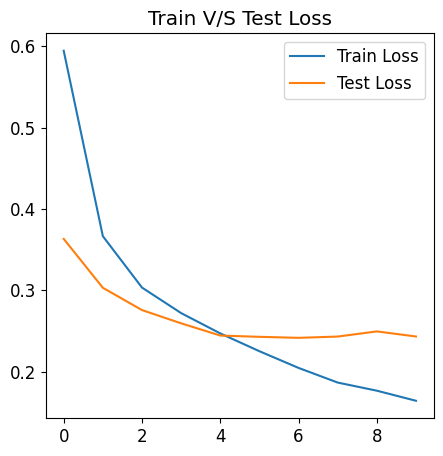

In [56]:
plt.figure(figsize = (5 , 5))
plt.plot(train_loss , label = "Train Loss")
plt.plot(test_loss , label = "Test Loss")
plt.legend()
plt.title("Train V/S Test Loss")

plt.show()

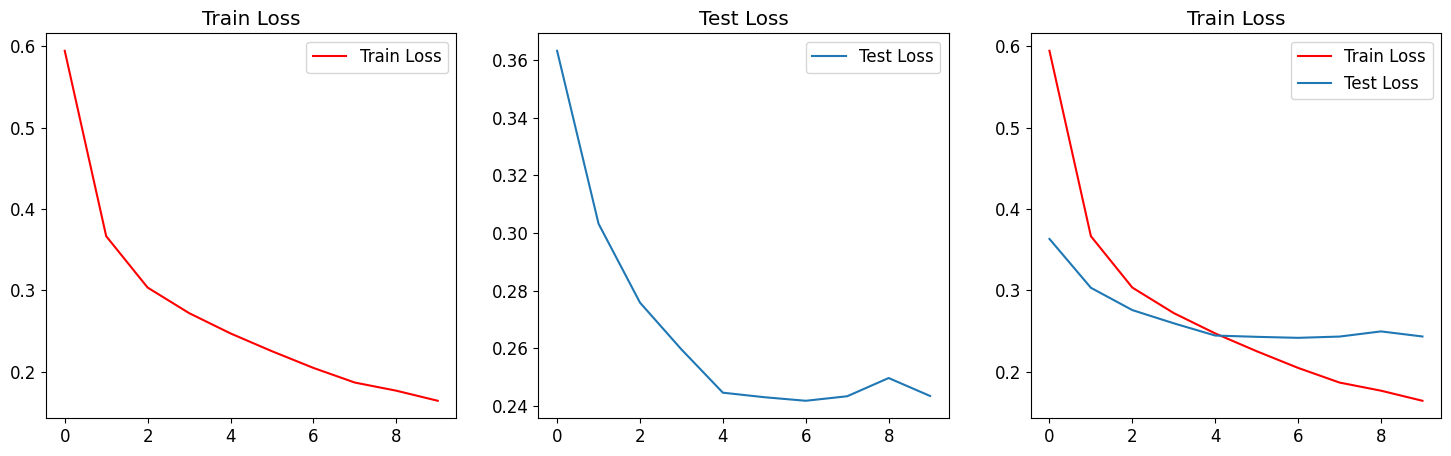

In [55]:
fig , axes = plt.subplots(1 , 3 , figsize = (18 , 5))

axes[0].plot(train_loss , label = "Train Loss" , color = "red")
axes[0].set_title("Train Loss")
axes[0].legend()

axes[1].plot(test_loss , label = "Test Loss")
axes[1].set_title("Test Loss")
axes[1].legend()

axes[2].plot(train_loss , label = "Train Loss" , color = "red")
axes[2].plot(test_loss , label = "Test Loss")
axes[2].set_title("Train Loss")
axes[2].legend()


plt.show()

Evaluating: 100%|██████████| 157/157 [00:04<00:00, 36.37it/s] 

Test Loss: 0.2405
Test Accuracy: 92.04%
Correct predictions: 9204/10000


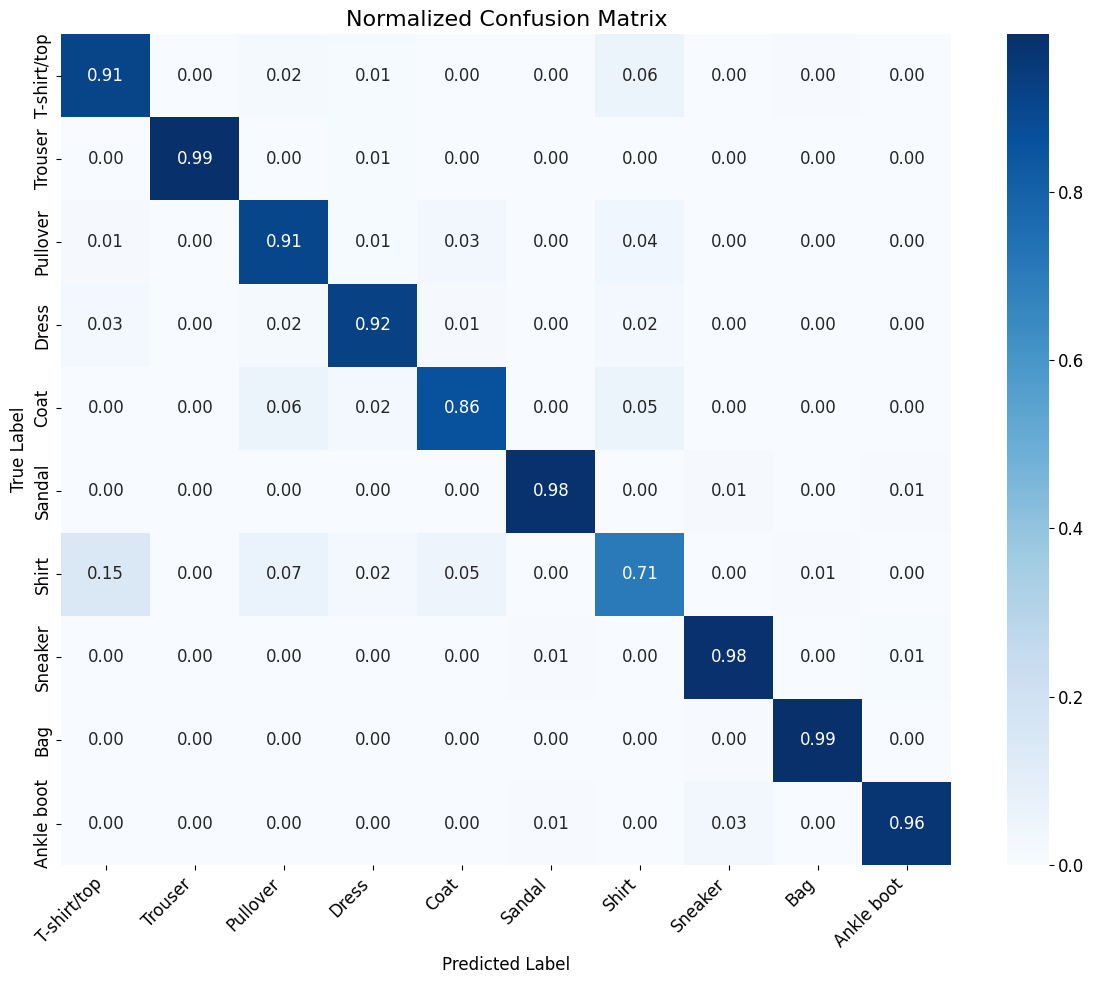

Classification Report:
              precision    recall  f1-score   support

 T-shirt/top      0.829     0.910     0.867      1000
     Trouser      0.997     0.987     0.992      1000
    Pullover      0.850     0.906     0.877      1000
       Dress      0.925     0.920     0.922      1000
        Coat      0.894     0.861     0.877      1000
      Sandal      0.987     0.978     0.982      1000
       Shirt      0.803     0.709     0.753      1000
     Sneaker      0.951     0.983     0.967      1000
         Bag      0.988     0.987     0.987      1000
  Ankle boot      0.982     0.963     0.972      1000

    accuracy                          0.920     10000
   macro avg      0.920     0.920     0.920     10000
weighted avg      0.920     0.920     0.920     10000



In [58]:
# Evaluate the model on the test set
from tqdm import tqdm


def evaluate_model(model, test_loader, criterion):
    """Evaluate the model on the test set."""
    # Set model to evaluation mode
    model.eval()

    # Tracking metrics
    test_loss = 0.0
    correct = 0
    total = 0

    # Store all predictions and targets for confusion matrix
    all_predictions = []
    all_targets = []

    # No gradients needed for evaluation
    with torch.no_grad():
        for inputs, targets in tqdm(test_loader, desc="Evaluating"):
            # Move data to device
            inputs, targets = inputs.to(device), targets.to(device)

            # Forward pass
            outputs = model(inputs)

            # Calculate loss
            loss = criterion(outputs, targets)
            test_loss += loss.item()

            # Get predictions
            _, predicted = outputs.max(1)

            # Update statistics
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

            # Store for confusion matrix
            all_predictions.extend(predicted.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

    # Calculate metrics
    test_loss /= len(test_loader)
    test_accuracy = 100. * correct / total

    # Print results
    print(f"Test Loss: {test_loss:.4f}")
    print(f"Test Accuracy: {test_accuracy:.2f}%")
    print(f"Correct predictions: {correct}/{total}")

    return test_loss, test_accuracy, all_predictions, all_targets

# Run evaluation
test_loss, test_accuracy, all_predictions, all_targets = evaluate_model(model, test_loader, criterion)

# Create and plot confusion matrix
def plot_confusion_matrix(y_true, y_pred, class_names):
    """Create and plot a confusion matrix."""
    # Calculate confusion matrix
    cm = confusion_matrix(y_true, y_pred)

    # Normalize by row (true labels)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    # Plot
    plt.figure(figsize=(12, 10))

    # Create a heatmap
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)

    plt.title('Normalized Confusion Matrix', fontsize=16)
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    # Print classification report
    print("Classification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

# Plot confusion matrix
plot_confusion_matrix(all_targets, all_predictions, class_names)